In [1]:
import numpy as np

X = 2* np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

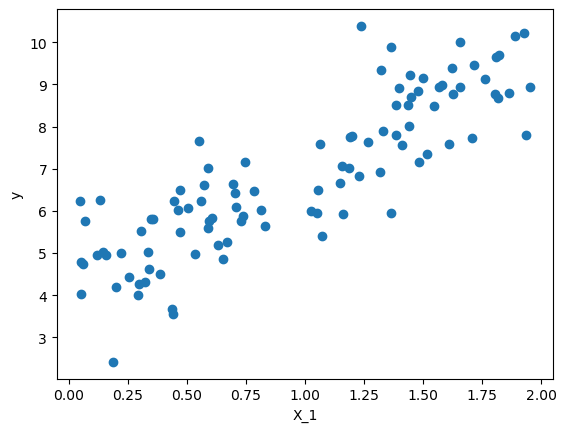

In [2]:
import matplotlib.pyplot as plt

plt.scatter(X, y)
plt.xlabel("X_1")
plt.ylabel("y")
plt.show()

In [3]:
?np.linalg.inv

Signature:       np.linalg.inv(a)
Call signature:  np.linalg.inv(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function inv at 0x7fadb04acfe0>
File:            ~/anaconda3/lib/python3.13/site-packages/numpy/linalg/_linalg.py
Docstring:      
Compute the inverse of a matrix.

Given a square matrix `a`, return the matrix `ainv` satisfying
``a @ ainv = ainv @ a = eye(a.shape[0])``.

Parameters
----------
a : (..., M, M) array_like
    Matrix to be inverted.

Returns
-------
ainv : (..., M, M) ndarray or matrix
    Inverse of the matrix `a`.

Raises
------
LinAlgError
    If `a` is not square or inversion fails.

See Also
--------
scipy.linalg.inv : Similar function in SciPy.
numpy.linalg.cond : Compute the condition number of a matrix.
numpy.linalg.svd : Compute the singular value decomposition of a matrix.

Notes
-----
Broadcasting rules apply, see the `numpy.linalg` documentation for
details.

If `a` is detected to be singular, a `LinAlgError` is raised. I

In [4]:
X_b = np.c_[np.ones((100, 1)),  X]

In [5]:
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)

In [6]:
theta_best

array([[4.24193033],
       [2.69800028]])

In [7]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b.dot(theta_best)
y_predict

array([[4.24193033],
       [9.63793088]])

In [8]:
X_new_b

array([[1., 0.],
       [1., 2.]])

In [9]:
theta = np.linalg.inv(X_b.T.dot(X_b)) @ X_b.T @ y

In [10]:
theta

array([[4.24193033],
       [2.69800028]])

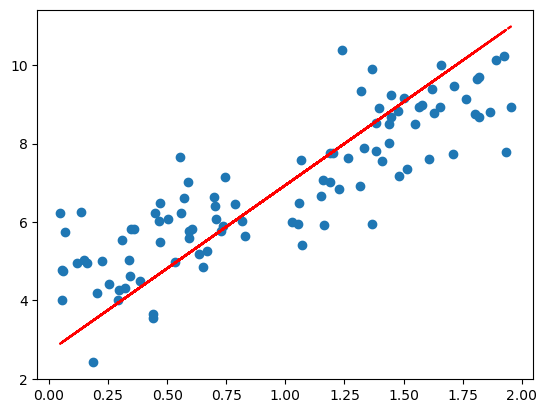

In [11]:
plt.scatter(X,y)
plt.plot(X, theta[0]*X + theta[1], 'r--')
plt.show()

## Gradient Descent

In [12]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X, y)
lin_reg.intercept_, lin_reg.coef_

(array([4.24193033]), array([[2.69800028]]))

In [13]:
distance = np.power(theta_best[0] * X + theta_best[1] - y, 2)

In [14]:
1/len(X) * np.sum(distance)

np.float64(1.6316711924889404)

In [31]:
eta = 0.5 # learning rate
n_iterations = 1000
m = 100
theta = np.random.randn(2, 1) 

theta_timeline = []
theta_timeline.append(theta)

for iteration in range(n_iterations): 
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
    theta = theta - eta * gradients
    theta_timeline.append(theta)

In [32]:
theta

array([[-5.92396902e+40],
       [-6.75790958e+40]])

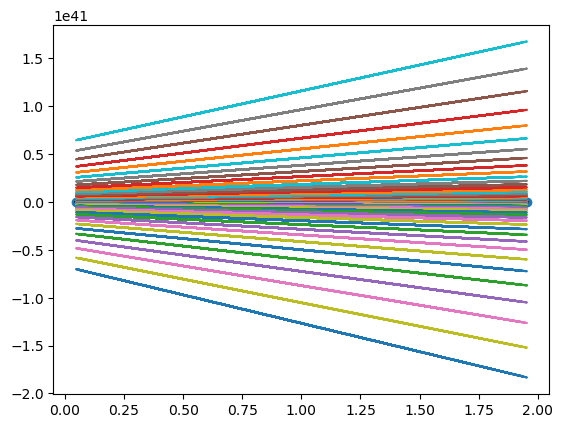

In [33]:
plt.scatter(X, y)
for t in theta_timeline: 
    plt.plot(X, t[0]* X + t[1], linestyle = "-")

plt.show()